# 6. Aperture distribution (descriptive)

**Purpose:** describe which f-numbers were shot. Each burst counts as one image, the same as notebook 05.

**Aperture** is the `FNumber` tag. It is read for every image; an image without it is skipped with a warning.

**Burst rule:** consecutive files in the same folder with an identical `DateTimeOriginal` (the same second) form one burst. The first frame represents it, including its aperture.

**Caveat:** frames inside one burst can have different apertures. Only the first frame's aperture is used here.

**Data:** served from the `.cache/` folder when it is less than one day old. Change `DIRECTORY` and `DEPTH` below to point elsewhere.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent  # run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import focal_band, group_bursts, load_records

DIRECTORY, DEPTH = r"D:\DCIM", 1
records = load_records(DIRECTORY, DEPTH)
bursts = group_bursts(records)

## Summary

In [2]:
stops = bursts["aperture"].value_counts().sort_index()
summary = pd.Series({
    "Images with an f-number": len(records),
    "Bursts (each counted once)": len(bursts),
    "Distinct f-stops used": len(stops),
    "Lowest f-number used": f"f/{bursts['aperture'].min():g}",
    "Highest f-number used": f"f/{bursts['aperture'].max():g}",
    "Most used": f"f/{stops.idxmax():g} ({stops.max() / stops.sum() * 100:.1f}% of bursts)",
})
summary.to_frame("value")

,value
Images with an f-number,885
Bursts (each counted once),877
Distinct f-stops used,16
Lowest f-number used,f/3.5
Highest f-number used,f/20
Most used,f/5.6 (20.0% of bursts)


## Bursts per f-stop
One bar per f-stop used, counting each burst once.

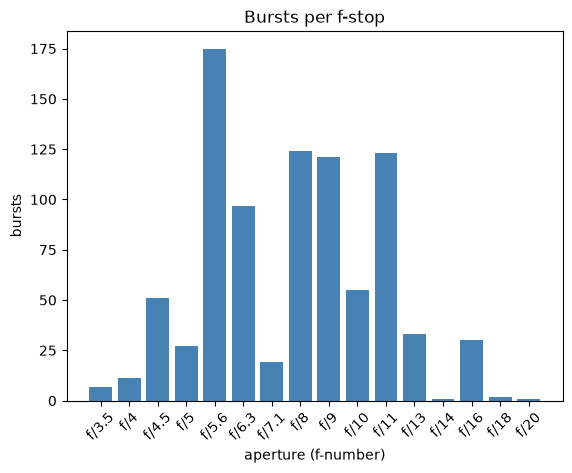

,bursts,share %
aperture,,
3.5,7,0.8
4.0,11,1.3
4.5,51,5.8
5.0,27,3.1
5.6,175,20.0
6.3,97,11.1
7.1,19,2.2
8.0,124,14.1
9.0,121,13.8


In [3]:
labels = [f"f/{v:g}" for v in stops.index]
plt.bar(labels, stops.values, color="steelblue")
plt.xlabel("aperture (f-number)")
plt.ylabel("bursts")
plt.title("Bursts per f-stop")
plt.xticks(rotation=45)
plt.show()

table = stops.rename("bursts").to_frame()
table["share %"] = (table["bursts"] / table["bursts"].sum() * 100).round(1)
table

## Every image vs bursts per f-stop
Shows where merging bursts changes the count for each f-stop.

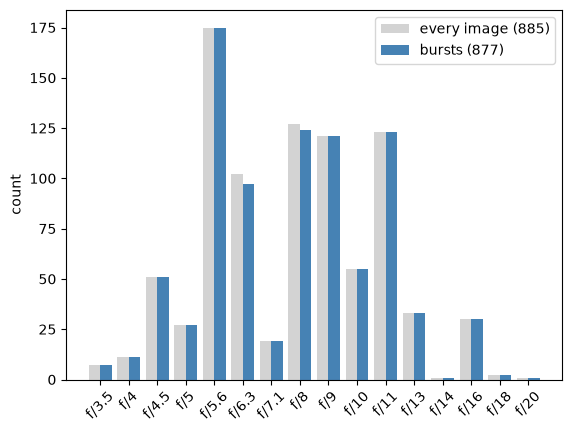

Total images merged away: 8 of 885


,images merged away
aperture,
6.3,5
8.0,3


In [4]:
images_per_stop = records["aperture"].value_counts().sort_index()
all_stops = images_per_stop.index
bursts_per_stop = bursts["aperture"].value_counts().reindex(all_stops, fill_value=0)
x = np.arange(len(all_stops))
width = 0.4
plt.bar(x - width / 2, images_per_stop.values, width, label=f"every image ({len(records)})", color="lightgray")
plt.bar(x + width / 2, bursts_per_stop.values, width, label=f"bursts ({len(bursts)})", color="steelblue")
plt.xticks(x, [f"f/{v:g}" for v in all_stops], rotation=45)
plt.ylabel("count")
plt.legend()
plt.show()

merged = (images_per_stop - bursts_per_stop).rename("images merged away")
print(f"Total images merged away: {merged.sum()} of {len(records)}")
merged[merged > 0].to_frame()

## Shares by aperture class
Conventional classes: **wide** (f/4.5 and wider), **mid** (f/5 to f/8) and **stopped down** (f/9 and narrower). A value on an edge goes to the wider class.

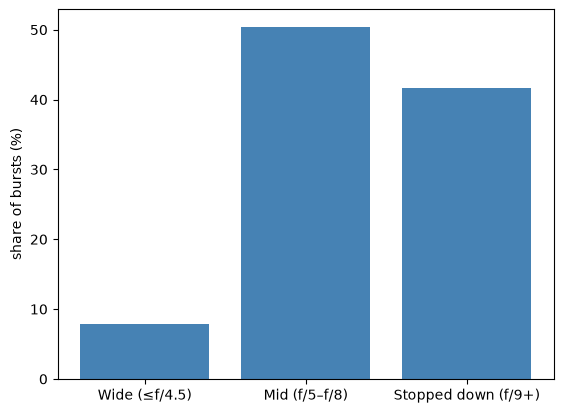

,bursts,share %
aperture,,
Wide (≤f/4.5),69,7.9
Mid (f/5–f/8),442,50.4
Stopped down (f/9+),366,41.7


In [5]:
APERTURE_EDGES = [0, 4.5, 8, 100]
APERTURE_LABELS = ["Wide (≤f/4.5)", "Mid (f/5–f/8)", "Stopped down (f/9+)"]
aperture_class = pd.cut(bursts["aperture"], bins=APERTURE_EDGES, labels=APERTURE_LABELS)
class_table = aperture_class.value_counts(sort=False).rename("bursts").to_frame()
class_table["share %"] = (class_table["bursts"] / class_table["bursts"].sum() * 100).round(1)

plt.bar(class_table.index.astype(str), class_table["share %"], color="steelblue")
plt.ylabel("share of bursts (%)")
plt.show()
class_table

## Cumulative distribution of burst f-numbers
Share of bursts at or below each f-number. Markers show the quartiles.

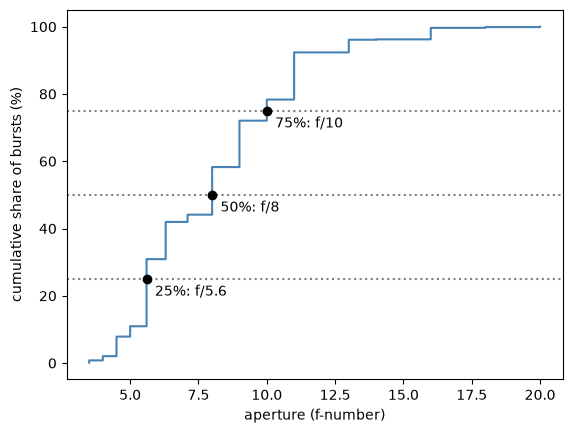

In [6]:
ordered = np.sort(bursts["aperture"].to_numpy())
cumulative = np.arange(1, len(ordered) + 1) / len(ordered) * 100
plt.step(ordered, cumulative, where="post", color="steelblue")
for q in [25, 50, 75]:
    value = np.percentile(ordered, q)
    plt.axhline(q, ls=":", color="gray")
    plt.plot([value], [q], "o", color="black")
    plt.annotate(f"{q}%: f/{value:g}", (value, q), textcoords="offset points", xytext=(6, -12))
plt.xlabel("aperture (f-number)")
plt.ylabel("cumulative share of bursts (%)")
plt.show()

## Takeaways
Figures from this run (885 images, 877 bursts). They describe this folder only and change if the folder changes.

1. **Merging barely changes the picture.** 8 of 885 images merged into bursts (5 at f/6.3, 3 at f/8), so 877 bursts. The burst rule does not change the aperture conclusions here.
2. **Mid apertures dominate.** f/5 to f/8 holds 50.4% of bursts, stopped down (f/9 and narrower) 41.7%, and wide (f/4.5 and wider) 7.9%.
3. **f/5.6 is the most used stop** at 20.0% of bursts, followed by f/8 (14.1%), f/11 (14.0%) and f/9 (13.8%).
4. **Wide openings are rare.** f/3.5 was used on 7 bursts and f/4 on 11. Notebook 07 shows where they were used.